# Experiment 1 — Single Layer Perceptron for Banknote Authentication

**Course:** CS3807 – Deep Learning Laboratory
**Task:** Implement a Single Layer Perceptron from scratch and use it to tell genuine banknotes from forged ones.

This notebook follows the lab manual task-by-task (Task 1 to Task 6), and then goes a little further —
learning rate comparison, a decision boundary view, a sanity check against Scikit-learn's own Perceptron,
and a quick look at why a single neuron gives up on XOR. Nothing here is hard-coded to this dataset alone;
the plotting and training utilities are written so the same notebook skeleton can be pointed at a different
CSV next time with minimal changes.


## 0. Setup — imports, reproducibility, and a consistent plotting style

Before touching any data, we fix the look and feel of every figure we're going to produce (Times New Roman, bold axes/legends, 600 dpi EPS export) in one place, so we never have to repeat this styling code cell after cell.

In [1]:
# Core numerical / data-handling stack
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Metrics + baseline model (used only for the optional sanity-check comparison,
# the perceptron itself is implemented from scratch further below)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)
from sklearn.linear_model import Perceptron as SklearnPerceptron

from pathlib import Path

# Reproducibility: a perceptron's convergence path depends on initial weights
# and on how the training rows are shuffled each epoch, so we pin the seed.
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Every figure in this notebook is saved as a vector EPS at 600 dpi and dropped
# in ./figures/, since that's what the lab asks for.
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# One shared style so every plot looks like it belongs to the same report:
# Times New Roman body text, bold axis labels, bold legends.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 13,
    "axes.labelsize": 14,
    "axes.labelweight": "bold",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.fontsize": 13,
    "legend.title_fontsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
})


def save_fig(fig, name):
    """Save a figure the way this lab wants it: vector EPS, 600 dpi, tight box.

    Keeping this in one function means every plot in the notebook is exported
    identically, and if the export spec ever changes we fix it in exactly one place.
    """
    fig.savefig(FIG_DIR / f"{name}.eps", format="eps", dpi=600)
    print(f"Saved -> {FIG_DIR / f'{name}.eps'}")


def bold_legend(ax, **kwargs):
    """Attach a legend to `ax` with a bold title and bold entry labels."""
    leg = ax.legend(**kwargs)
    if leg.get_title() is not None:
        leg.get_title().set_fontweight("bold")
    for text in leg.get_texts():
        text.set_fontweight("bold")
    return leg

## Task 1 — Load the dataset and get to know it

The UCI file ships with no header row, so we attach column names ourselves using the variable descriptions from the dataset page before looking at shape, dtypes, missing values and summary statistics.

In [2]:
COLUMN_NAMES = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv("data_banknote_authentication.txt", header=None, names=COLUMN_NAMES)

print(f"Dataset shape: {df.shape[0]} samples x {df.shape[1]} columns\n")
df.head()

Dataset shape: 1372 samples x 5 columns



,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
# Dtypes and a missing-value check in one go — the manual promises zero missing
# values, but it's good practice to verify that ourselves rather than take it on faith.
print(df.dtypes, "\n")
print("Missing values per column:")
print(df.isnull().sum())

variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object 

Missing values per column:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [4]:
# Class balance matters a lot for a perceptron: a very skewed dataset can make a
# lazy "always predict the majority class" rule look deceptively accurate.
class_counts = df["class"].value_counts().sort_index()
class_counts.index = ["Authentic (0)", "Forged (1)"]
print(class_counts)

Authentic (0)    762
Forged (1)       610
Name: count, dtype: int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
class,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


## Task 2 — Exploratory Data Analysis

Four plots are asked for: histograms, a correlation heatmap, a scatter plot, and boxplots. Per the lab rules we club all of these into as few multi-panel figures as sensibly possible, each subplot carrying its own caption.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/01_feature_histograms.eps


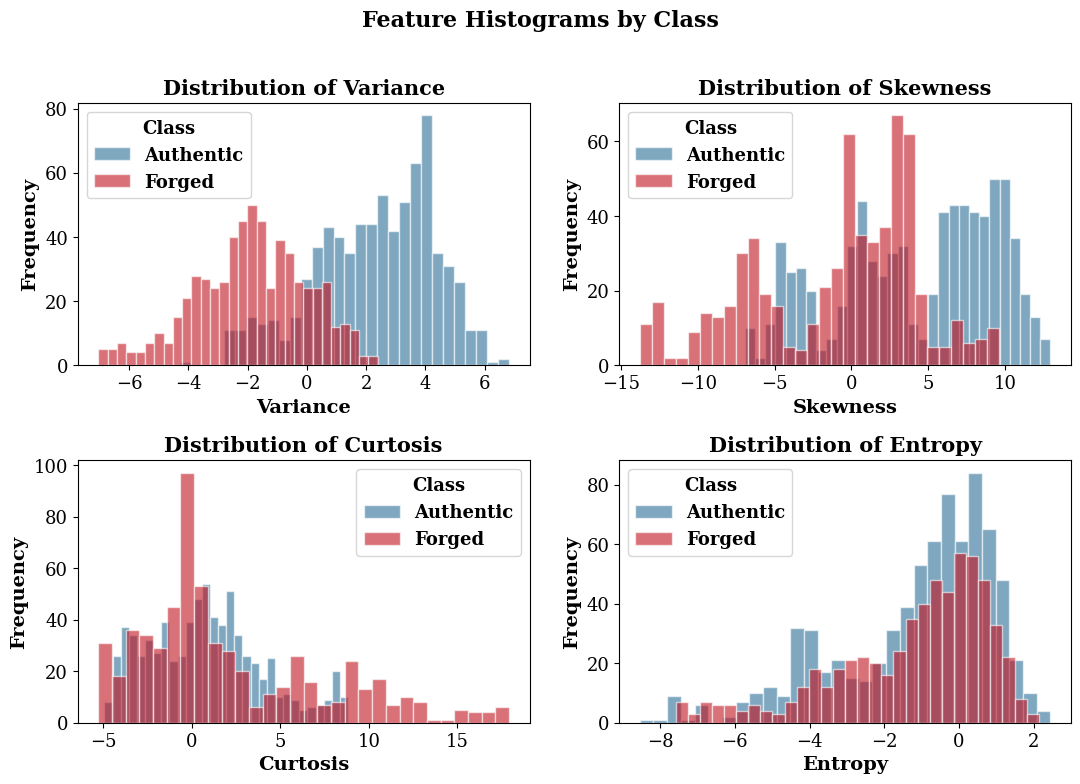

In [6]:
FEATURES = ["variance", "skewness", "curtosis", "entropy"]

# --- Figure 1: distribution of every feature, split by class -------------------
# One 2x2 grid of histograms rather than four separate figures.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), FEATURES):
    for cls, colour, label in [(0, "#2a6f97", "Authentic"), (1, "#c1121f", "Forged")]:
        ax.hist(df.loc[df["class"] == cls, feat], bins=30, alpha=0.6,
                color=colour, label=label, edgecolor="white")
    ax.set_xlabel(feat.capitalize())
    ax.set_ylabel("Frequency")
    ax.set_title(f"Distribution of {feat.capitalize()}")
    bold_legend(ax, title="Class")

fig.suptitle("Feature Histograms by Class", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
save_fig(fig, "01_feature_histograms")
plt.show()

Saved -> figures/02_correlation_heatmap.eps


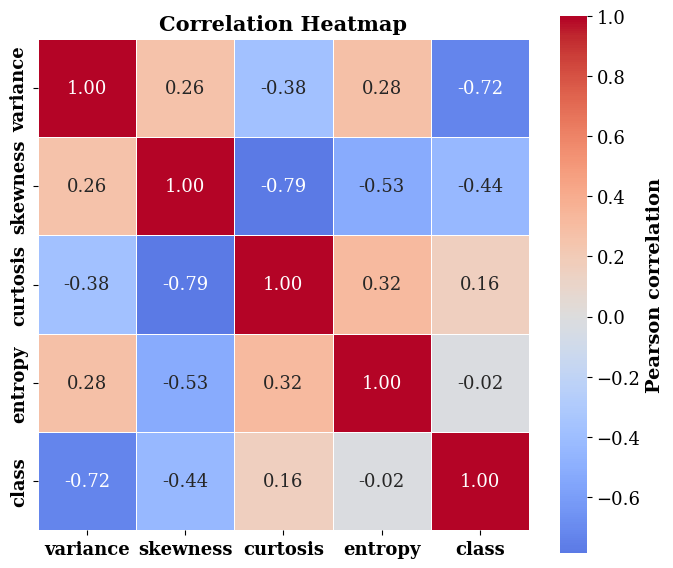

In [7]:
# --- Figure 2: correlation heatmap ----------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
corr = df[FEATURES + ["class"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap")
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
fig.tight_layout()
save_fig(fig, "02_correlation_heatmap")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/03_scatter_plots.eps


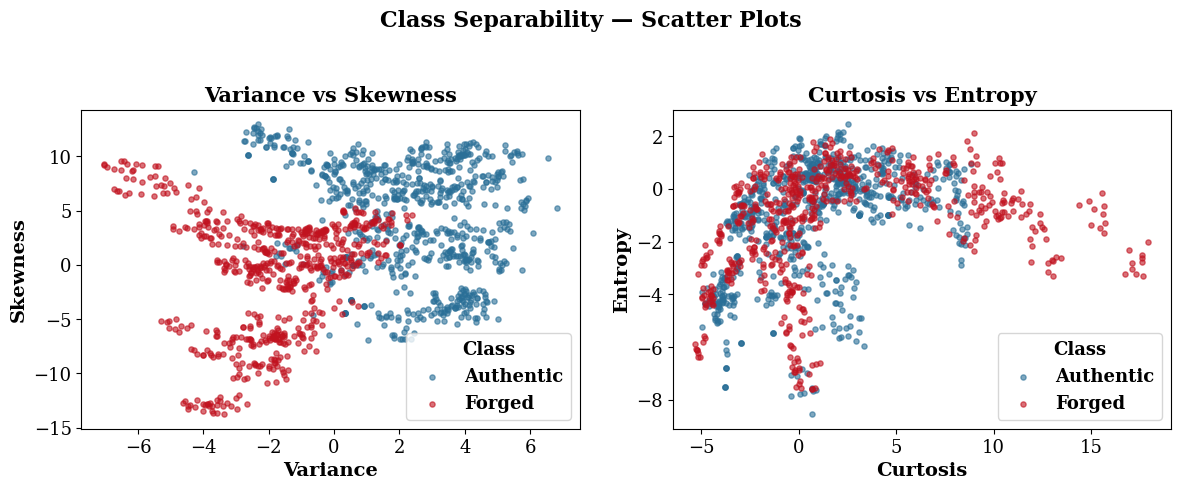

In [8]:
# --- Figure 3: scatter plot(s) to eyeball linear separability -------------------
# variance-vs-skewness is the classic pairing for this dataset, but curtosis and
# entropy carry useful signal too, so we show both the "headline" pair and the
# runner-up pair side by side instead of picking arbitrarily.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pairs = [("variance", "skewness"), ("curtosis", "entropy")]
for ax, (fx, fy) in zip(axes, pairs):
    for cls, colour, label in [(0, "#2a6f97", "Authentic"), (1, "#c1121f", "Forged")]:
        subset = df[df["class"] == cls]
        ax.scatter(subset[fx], subset[fy], s=14, alpha=0.6, color=colour, label=label)
    ax.set_xlabel(fx.capitalize())
    ax.set_ylabel(fy.capitalize())
    ax.set_title(f"{fx.capitalize()} vs {fy.capitalize()}")
    bold_legend(ax, title="Class")

fig.suptitle("Class Separability — Scatter Plots", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "03_scatter_plots")
plt.show()

Saved -> figures/04_boxplots.eps


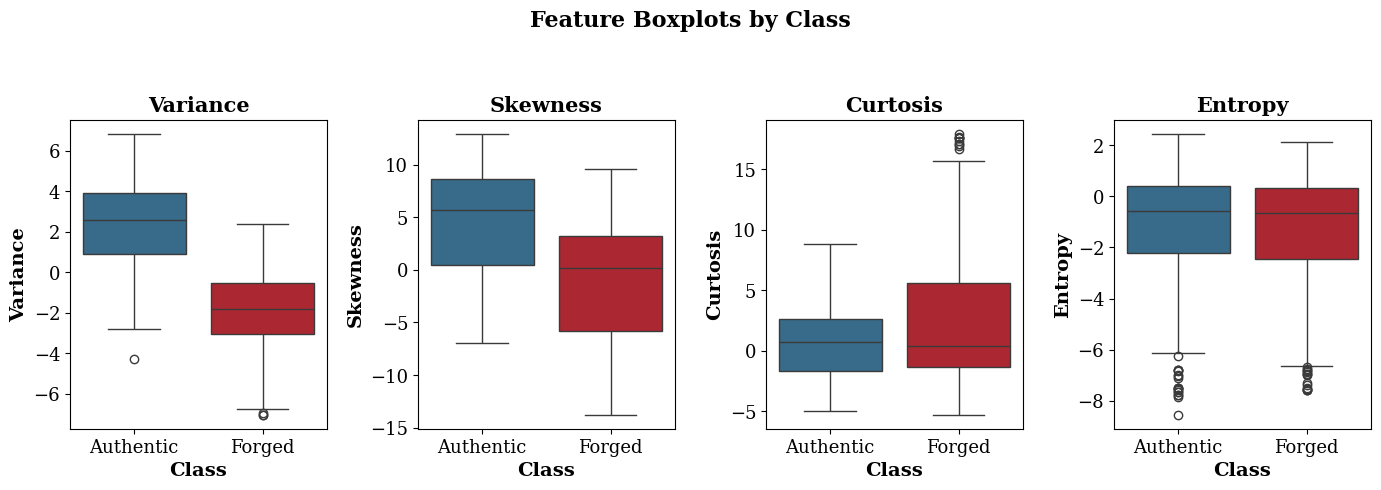

In [9]:
# --- Figure 4: boxplots to spot spread and outliers per feature ----------------
fig, axes = plt.subplots(1, 4, figsize=(14, 5), sharey=False)
for ax, feat in zip(axes, FEATURES):
    sns.boxplot(x="class", y=feat, hue="class", data=df, ax=ax,
                palette={0: "#2a6f97", 1: "#c1121f"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Authentic", "Forged"])
    ax.set_xlabel("Class")
    ax.set_ylabel(feat.capitalize())
    ax.set_title(feat.capitalize())

fig.suptitle("Feature Boxplots by Class", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, "04_boxplots")
plt.show()

## Task 3 — Preprocessing

Two things need doing: put every feature on the same scale, and carve out a held-out test set. We standardise (zero mean, unit variance) rather than min-max scale, since the perceptron's weight update is sensitive to raw feature magnitude and standardisation keeps all four features contributing on comparable footing. Scaling parameters are fit on the training split only, so no information from the test set leaks into preprocessing.

In [10]:
X = df[FEATURES].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)


def standardize_fit(X_train):
    """Compute per-feature mean and std from the training data."""
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1.0  # guards against a constant column dividing by zero
    return mu, sigma


def standardize_apply(X, mu, sigma):
    """Apply a previously-fit mean/std standardisation to `X`."""
    return (X - mu) / sigma


mu, sigma = standardize_fit(X_train_raw)
X_train = standardize_apply(X_train_raw, mu, sigma)
X_test = standardize_apply(X_test_raw, mu, sigma)

print(f"Training samples: {X_train.shape[0]}  |  Test samples: {X_test.shape[0]}")
print(f"Training class balance: {np.bincount(y_train)}  (0=Authentic, 1=Forged)")
print(f"Test class balance:     {np.bincount(y_test)}")
print("\nFeature means after standardisation (train):", np.round(X_train.mean(axis=0), 4))
print("Feature stds  after standardisation (train):", np.round(X_train.std(axis=0), 4))

Training samples: 1097  |  Test samples: 275
Training class balance: [609 488]  (0=Authentic, 1=Forged)
Test class balance:     [153 122]

Feature means after standardisation (train): [-0. -0. -0.  0.]
Feature stds  after standardisation (train): [1. 1. 1. 1.]


## Task 4 — Single Layer Perceptron, built from scratch

A small, self-contained class: it owns its weights and bias, applies the step activation, and updates itself with the classic perceptron learning rule `w <- w + eta * (y - y_hat) * x`, `b <- b + eta * (y - y_hat)`. Keeping it as one class (rather than loose functions) makes it trivial to train several instances side by side later, e.g. for the learning-rate comparison.

In [11]:
class Perceptron:
    """A single-layer perceptron trained with the classic perceptron learning rule.

    This is deliberately framework-free — plain NumPy — so every moving part
    (weight init, the step activation, the update rule) is visible and editable.
    """

    def __init__(self, n_features, learning_rate=0.01, n_epochs=50, random_state=None):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        rng_local = np.random.default_rng(random_state)
        # Small random weights break symmetry; a zero bias is a neutral starting point.
        self.weights = rng_local.normal(loc=0.0, scale=0.01, size=n_features)
        self.bias = 0.0

        # Filled in during training, used for the "Weight Evolution" / "Bias Evolution"
        # / "Training Error vs Epoch" plots the lab asks for.
        self.history = {"epoch": [], "misclassified": [], "weights": [], "bias": []}

    @staticmethod
    def step_activation(z):
        """Classic Heaviside step: 1 if z >= 0, else 0."""
        return np.where(z >= 0, 1, 0)

    def forward(self, X):
        """Weighted sum followed by the step activation -> class prediction(s)."""
        z = X @ self.weights + self.bias
        return self.step_activation(z)

    def predict(self, X):
        return self.forward(X)

    def fit(self, X, y, verbose=True):
        """Train with the perceptron learning rule, one misclassified-sample update at a time.

        Every sample that the current weights get wrong nudges the weights and bias
        a little in the direction that would have fixed that particular mistake.
        One full pass over the training set is one epoch.
        """
        n_samples = X.shape[0]

        for epoch in range(1, self.n_epochs + 1):
            misclassified = 0
            # Shuffle each epoch so the update order doesn't bias the walk.
            order = rng.permutation(n_samples)

            for idx in order:
                xi, target = X[idx], y[idx]
                prediction = self.step_activation(xi @ self.weights + self.bias)
                error = target - prediction

                if error != 0:
                    misclassified += 1
                    self.weights += self.learning_rate * error * xi
                    self.bias += self.learning_rate * error

            self.history["epoch"].append(epoch)
            self.history["misclassified"].append(misclassified)
            self.history["weights"].append(self.weights.copy())
            self.history["bias"].append(self.bias)

            if verbose:
                w_str = ", ".join(f"{w:.4f}" for w in self.weights)
                print(f"Epoch {epoch:3d} | Misclassified: {misclassified:4d} "
                      f"| Weights: [{w_str}] | Bias: {self.bias:.4f}")

            if misclassified == 0:
                if verbose:
                    print(f"\nConverged after {epoch} epoch(s) — training set is fully separated.")
                break

        return self

## Task 5 — Model Training

Train on the standardised training split and watch the per-epoch log: misclassified count, updated weights, updated bias. Training stops early if the perceptron ever gets a perfect epoch.

In [12]:
model = Perceptron(n_features=X_train.shape[1], learning_rate=0.01, n_epochs=50,
                    random_state=RANDOM_STATE)
model.fit(X_train, y_train, verbose=True)

Epoch   1 | Misclassified:   53 | Weights: [-0.0664, -0.0648, -0.0695, 0.0034] | Bias: -0.0300
Epoch   2 | Misclassified:   30 | Weights: [-0.0849, -0.0754, -0.0792, -0.0119] | Bias: -0.0500
Epoch   3 | Misclassified:   25 | Weights: [-0.1022, -0.1226, -0.0645, -0.0014] | Bias: -0.0200
Epoch   4 | Misclassified:   20 | Weights: [-0.0907, -0.1130, -0.1000, -0.0157] | Bias: -0.0400
Epoch   5 | Misclassified:   22 | Weights: [-0.0995, -0.1142, -0.1079, 0.0077] | Bias: -0.0600
Epoch   6 | Misclassified:   30 | Weights: [-0.1317, -0.1390, -0.0984, -0.0125] | Bias: -0.0400
Epoch   7 | Misclassified:   22 | Weights: [-0.1147, -0.1396, -0.1193, -0.0071] | Bias: -0.0600
Epoch   8 | Misclassified:   20 | Weights: [-0.1185, -0.1452, -0.1280, -0.0048] | Bias: -0.0600
Epoch   9 | Misclassified:   19 | Weights: [-0.1182, -0.1503, -0.1401, -0.0090] | Bias: -0.0500
Epoch  10 | Misclassified:   24 | Weights: [-0.1421, -0.1720, -0.1180, -0.0071] | Bias: -0.0500
Epoch  11 | Misclassified:   23 | Weights:

Epoch  28 | Misclassified:   14 | Weights: [-0.1673, -0.2091, -0.1747, -0.0056] | Bias: -0.0800
Epoch  29 | Misclassified:   13 | Weights: [-0.1690, -0.2042, -0.1770, -0.0030] | Bias: -0.0900
Epoch  30 | Misclassified:   19 | Weights: [-0.1687, -0.2115, -0.1867, 0.0002] | Bias: -0.0800
Epoch  31 | Misclassified:   15 | Weights: [-0.1696, -0.2172, -0.1852, -0.0124] | Bias: -0.0700
Epoch  32 | Misclassified:   18 | Weights: [-0.1737, -0.2102, -0.1930, -0.0096] | Bias: -0.0700
Epoch  33 | Misclassified:   15 | Weights: [-0.1843, -0.2251, -0.1753, -0.0123] | Bias: -0.0600


Epoch  34 | Misclassified:   15 | Weights: [-0.1819, -0.2036, -0.1906, -0.0009] | Bias: -0.0900
Epoch  35 | Misclassified:   17 | Weights: [-0.1776, -0.2187, -0.1835, -0.0076] | Bias: -0.0800
Epoch  36 | Misclassified:   13 | Weights: [-0.1694, -0.2013, -0.2044, -0.0186] | Bias: -0.0900
Epoch  37 | Misclassified:   14 | Weights: [-0.1701, -0.1992, -0.2084, -0.0130] | Bias: -0.0900
Epoch  38 | Misclassified:   17 | Weights: [-0.1799, -0.2106, -0.1979, 0.0017] | Bias: -0.0800
Epoch  39 | Misclassified:   17 | Weights: [-0.1856, -0.2037, -0.1963, 0.0019] | Bias: -0.0900
Epoch  40 | Misclassified:   17 | Weights: [-0.1943, -0.2002, -0.1961, -0.0162] | Bias: -0.0800
Epoch  41 | Misclassified:   17 | Weights: [-0.1908, -0.2283, -0.1690, -0.0043] | Bias: -0.0900
Epoch  42 | Misclassified:   15 | Weights: [-0.1804, -0.2065, -0.2067, -0.0037] | Bias: -0.0800
Epoch  43 | Misclassified:   17 | Weights: [-0.1971, -0.2263, -0.1775, -0.0223] | Bias: -0.0700
Epoch  44 | Misclassified:   14 | Weights:

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/05_training_dynamics.eps


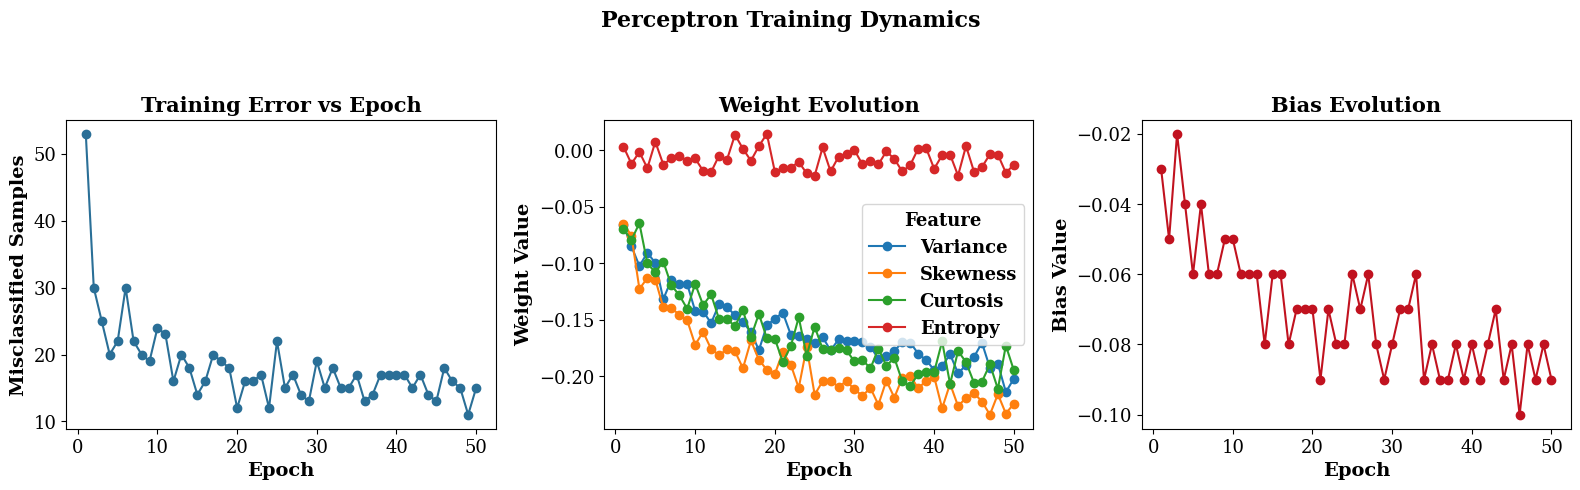

In [13]:
# --- Figure 5: training error, weight evolution and bias evolution, one figure --
epochs = model.history["epoch"]
weights_over_time = np.array(model.history["weights"])  # shape: (n_epochs_run, n_features)
bias_over_time = np.array(model.history["bias"])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].plot(epochs, model.history["misclassified"], marker="o", color="#2a6f97")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Misclassified Samples")
axes[0].set_title("Training Error vs Epoch")

for i, feat in enumerate(FEATURES):
    axes[1].plot(epochs, weights_over_time[:, i], marker="o", label=feat.capitalize())
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Weight Value")
axes[1].set_title("Weight Evolution")
bold_legend(axes[1], title="Feature")

axes[2].plot(epochs, bias_over_time, marker="o", color="#c1121f")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Bias Value")
axes[2].set_title("Bias Evolution")

fig.suptitle("Perceptron Training Dynamics", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, "05_training_dynamics")
plt.show()

## Task 6 — Model Evaluation

Standard classification metrics on the held-out test set, plus the confusion matrix the lab explicitly asks to be able to read off TP/FP/TN/FN from.

In [14]:
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
}

metrics_df = pd.DataFrame(metrics, index=["Scratch Perceptron"]).round(4)
metrics_df

,Accuracy,Precision,Recall,F1-score
Scratch Perceptron,0.9855,0.9683,1.0,0.9839


Saved -> figures/06_confusion_matrix.eps


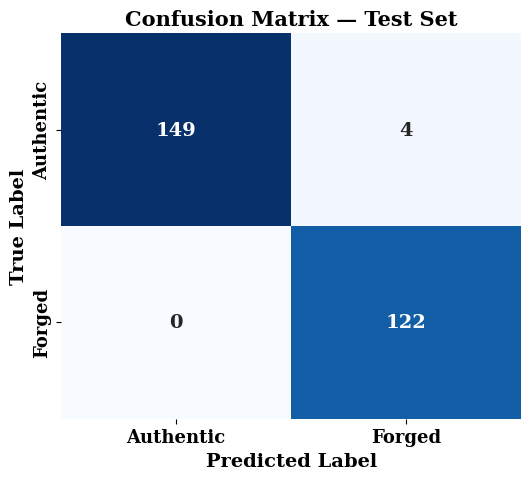

In [15]:
# --- Figure 6: confusion matrix -------------------------------------------------
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
            annot_kws={"fontweight": "bold", "fontsize": 14})
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix — Test Set")
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
fig.tight_layout()
save_fig(fig, "06_confusion_matrix")
plt.show()

## Task 7 — Effect of the Learning Rate

Same model, same data split, three learning rates. We train one fresh perceptron per rate (so none of them share weight history) and overlay their convergence curves.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/07_learning_rate_comparison.eps


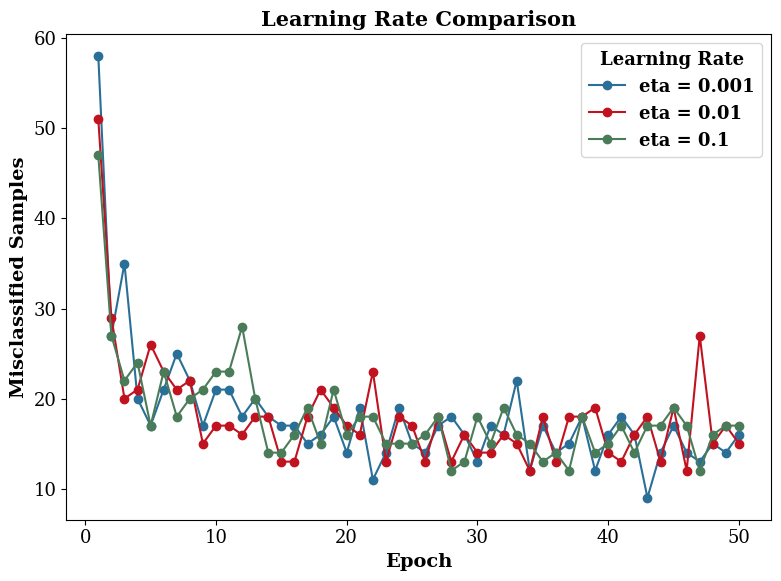

In [16]:
learning_rates = [0.001, 0.01, 0.1]
lr_histories = {}

for lr in learning_rates:
    m = Perceptron(n_features=X_train.shape[1], learning_rate=lr, n_epochs=50,
                   random_state=RANDOM_STATE)
    m.fit(X_train, y_train, verbose=False)
    lr_histories[lr] = m.history

# --- Figure 7: learning-rate comparison -----------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
colours = ["#2a6f97", "#c1121f", "#4a7c59"]
for (lr, hist), colour in zip(lr_histories.items(), colours):
    ax.plot(hist["epoch"], hist["misclassified"], marker="o", color=colour,
            label=f"eta = {lr}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Misclassified Samples")
ax.set_title("Learning Rate Comparison")
bold_legend(ax, title="Learning Rate")
fig.tight_layout()
save_fig(fig, "07_learning_rate_comparison")
plt.show()

In [17]:
# A quick numeric side-by-side of how many epochs each rate needed and where it
# landed on the test set, to sit next to the plot above.
lr_summary = []
for lr, hist in lr_histories.items():
    m = Perceptron(n_features=X_train.shape[1], learning_rate=lr, n_epochs=50,
                   random_state=RANDOM_STATE)
    m.fit(X_train, y_train, verbose=False)
    pred = m.predict(X_test)
    lr_summary.append({
        "Learning Rate": lr,
        "Epochs Run": hist["epoch"][-1],
        "Final Misclassified (train)": hist["misclassified"][-1],
        "Test Accuracy": accuracy_score(y_test, pred),
    })

pd.DataFrame(lr_summary)

,Learning Rate,Epochs Run,Final Misclassified (train),Test Accuracy
0,0.001,50,16,0.985455
1,0.010,50,15,0.992727
2,0.100,50,17,0.981818


## Decision Boundary (Optional)

A perceptron's decision boundary is a hyperplane, so to actually draw it we need to step down to two dimensions. We retrain a fresh perceptron on just `variance` and `skewness` — the pair that looked most separable in the EDA scatter plot — and draw the line the model settles on.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/08_decision_boundary.eps


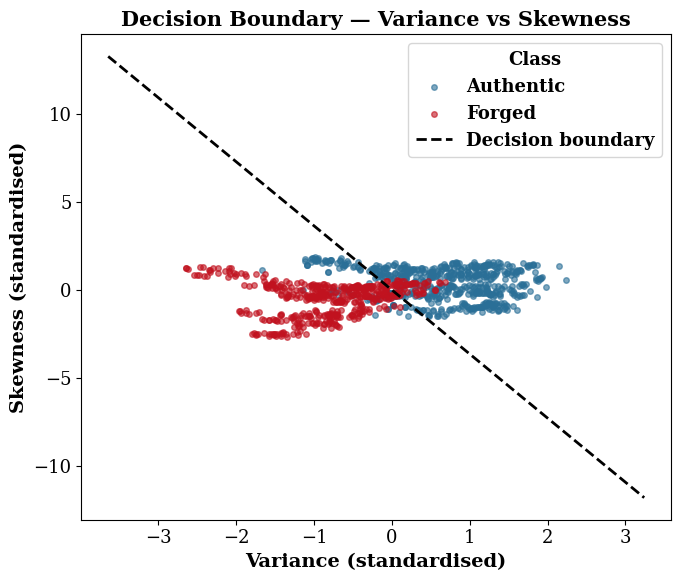

In [18]:
feat_x, feat_y = "variance", "skewness"
X_2d = df[[feat_x, feat_y]].to_numpy(dtype=float)
y_2d = df["class"].to_numpy(dtype=int)

X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d, y_2d, test_size=0.20, random_state=RANDOM_STATE, stratify=y_2d
)
mu_2d, sigma_2d = standardize_fit(X_2d_train)
X_2d_train_s = standardize_apply(X_2d_train, mu_2d, sigma_2d)
X_2d_test_s = standardize_apply(X_2d_test, mu_2d, sigma_2d)

model_2d = Perceptron(n_features=2, learning_rate=0.01, n_epochs=50, random_state=RANDOM_STATE)
model_2d.fit(X_2d_train_s, y_2d_train, verbose=False)

# --- Figure 8: decision boundary -------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
for cls, colour, label in [(0, "#2a6f97", "Authentic"), (1, "#c1121f", "Forged")]:
    subset = X_2d_train_s[y_2d_train == cls]
    ax.scatter(subset[:, 0], subset[:, 1], s=16, alpha=0.6, color=colour, label=label)

x_vals = np.linspace(X_2d_train_s[:, 0].min() - 1, X_2d_train_s[:, 0].max() + 1, 200)
w1, w2 = model_2d.weights
b = model_2d.bias
if abs(w2) > 1e-9:
    y_vals = -(w1 * x_vals + b) / w2
    ax.plot(x_vals, y_vals, color="black", linewidth=2, linestyle="--", label="Decision boundary")

ax.set_xlabel(feat_x.capitalize() + " (standardised)")
ax.set_ylabel(feat_y.capitalize() + " (standardised)")
ax.set_title("Decision Boundary — Variance vs Skewness")
bold_legend(ax, title="Class")
fig.tight_layout()
save_fig(fig, "08_decision_boundary")
plt.show()

## Additional Task — Scikit-learn Perceptron, as a sanity check

Same standardised training data, same test split, handed to `sklearn.linear_model.Perceptron`. This isn't a rematch so much as a sanity check that our from-scratch implementation lands in the same neighbourhood as a well-tested library.

In [19]:
sk_model = SklearnPerceptron(eta0=0.01, max_iter=50, random_state=RANDOM_STATE, tol=1e-3)
sk_model.fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)

comparison_df = pd.DataFrame({
    "Accuracy": [metrics["Accuracy"], accuracy_score(y_test, sk_pred)],
    "Precision": [metrics["Precision"], precision_score(y_test, sk_pred)],
    "Recall": [metrics["Recall"], recall_score(y_test, sk_pred)],
    "F1-score": [metrics["F1-score"], f1_score(y_test, sk_pred)],
}, index=["Scratch Perceptron", "Scikit-learn Perceptron"]).round(4)

comparison_df

,Accuracy,Precision,Recall,F1-score
Scratch Perceptron,0.9855,0.9683,1.0000,0.9839
Scikit-learn Perceptron,0.9673,0.9449,0.9836,0.9639


## Additional Task — Step vs. Sigmoid Activation

A quick side-by-side of the two activation shapes over the same input range, as a visual anchor for the differentiability discussion in the report.

Saved -> figures/09_step_vs_sigmoid.eps


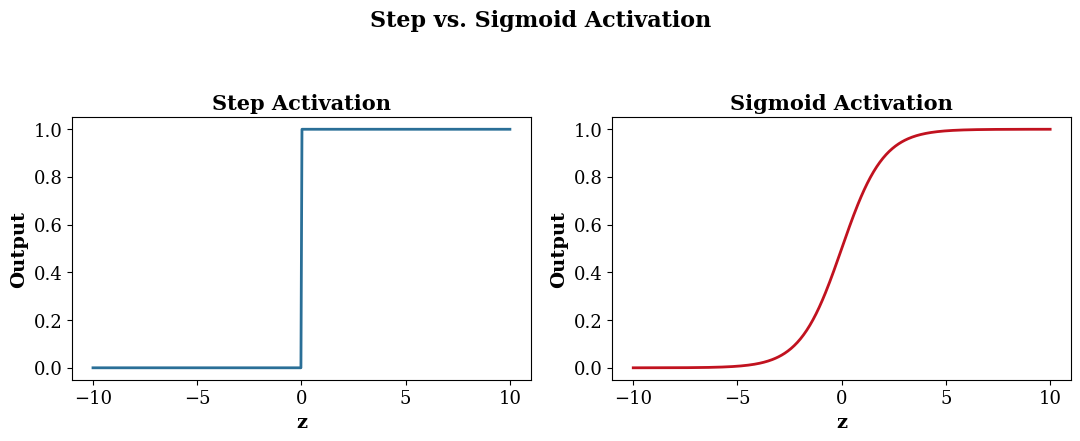

In [20]:
z = np.linspace(-10, 10, 400)
step_out = Perceptron.step_activation(z)
sigmoid_out = 1 / (1 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(z, step_out, color="#2a6f97", linewidth=2)
axes[0].set_xlabel("z")
axes[0].set_ylabel("Output")
axes[0].set_title("Step Activation")

axes[1].plot(z, sigmoid_out, color="#c1121f", linewidth=2)
axes[1].set_xlabel("z")
axes[1].set_ylabel("Output")
axes[1].set_title("Sigmoid Activation")

fig.suptitle("Step vs. Sigmoid Activation", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
save_fig(fig, "09_step_vs_sigmoid")
plt.show()

## Additional Task — Why a Single Perceptron Can't Learn XOR

Rather than just asserting this, we hand the perceptron the XOR truth table directly and watch its own training-error curve to see whether it ever reaches zero.

Saved -> figures/10_xor_training_error.eps


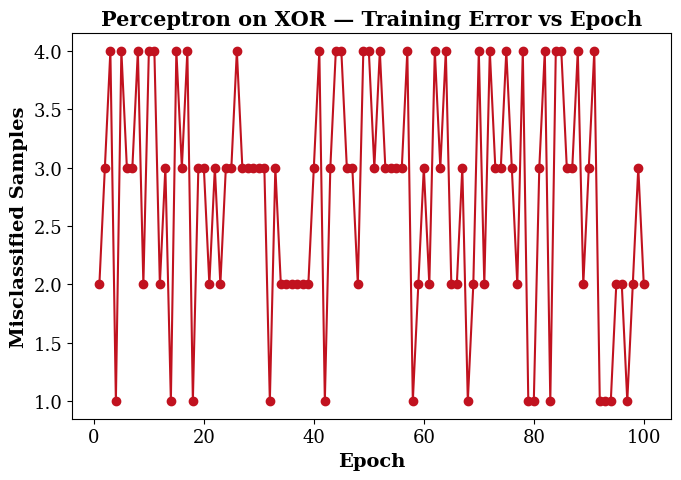

Final misclassified count on XOR: 2 out of 4 samples


In [21]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

xor_model = Perceptron(n_features=2, learning_rate=0.1, n_epochs=100, random_state=RANDOM_STATE)
xor_model.fit(X_xor, y_xor, verbose=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(xor_model.history["epoch"], xor_model.history["misclassified"],
        marker="o", color="#c1121f")
ax.set_xlabel("Epoch")
ax.set_ylabel("Misclassified Samples")
ax.set_title("Perceptron on XOR — Training Error vs Epoch")
fig.tight_layout()
save_fig(fig, "10_xor_training_error")
plt.show()

print("Final misclassified count on XOR:", xor_model.history["misclassified"][-1], "out of 4 samples")

## Additional Task — Effect of Feature Normalisation on Convergence

Same model and same learning rate, trained once on the raw (unscaled) features and once on the standardised features, so the convergence curves can be compared directly.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved -> figures/11_normalisation_effect.eps


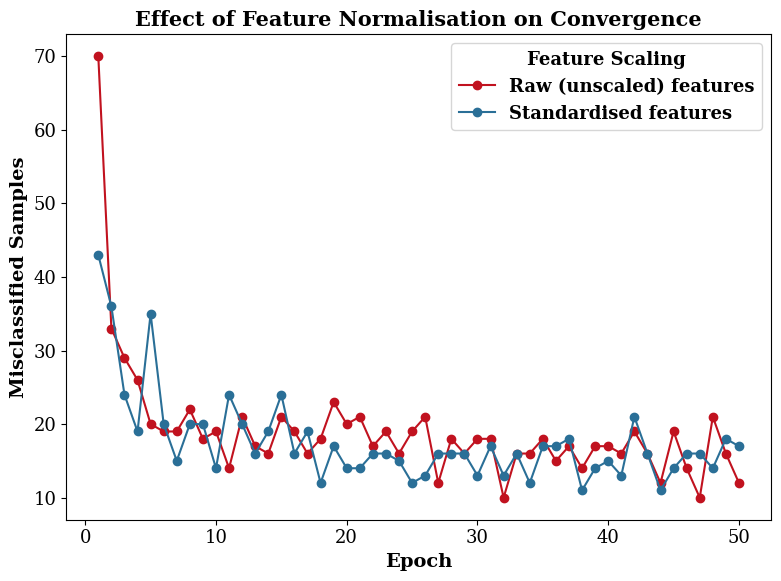

In [22]:
model_raw = Perceptron(n_features=X_train_raw.shape[1], learning_rate=0.01, n_epochs=50,
                       random_state=RANDOM_STATE)
model_raw.fit(X_train_raw, y_train, verbose=False)

model_scaled = Perceptron(n_features=X_train.shape[1], learning_rate=0.01, n_epochs=50,
                          random_state=RANDOM_STATE)
model_scaled.fit(X_train, y_train, verbose=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(model_raw.history["epoch"], model_raw.history["misclassified"],
        marker="o", color="#c1121f", label="Raw (unscaled) features")
ax.plot(model_scaled.history["epoch"], model_scaled.history["misclassified"],
        marker="o", color="#2a6f97", label="Standardised features")
ax.set_xlabel("Epoch")
ax.set_ylabel("Misclassified Samples")
ax.set_title("Effect of Feature Normalisation on Convergence")
bold_legend(ax, title="Feature Scaling")
fig.tight_layout()
save_fig(fig, "11_normalisation_effect")
plt.show()

## Additional Task — Logic Gates: OR, AND, NOT, and XOR (assigned separately)

A follow-up assignment asks for a perceptron trained on each of the basic logic gates, with the weights shown after *every single update* (not just every epoch) and the decision boundary re-plotted after each of those updates. OR, AND, and NOT are linearly separable, so the perceptron should converge in a handful of updates; XOR is the odd one out and is used below to pin down, concretely, the geometric reason it never converges.

In [23]:
def train_with_update_history(X, y, learning_rate=0.5, max_updates=30, random_state=0):
    """Train a perceptron and snapshot (weights, bias) after every individual
    weight update -- as opposed to Perceptron.fit, which only snapshots once per epoch.

    Stops early if a full pass over the data produces zero errors (converged),
    or once `max_updates` individual corrections have been made (safety cap for
    gates, like XOR, that never converge).
    """
    n_samples, n_features = X.shape
    rng_local = np.random.default_rng(random_state)
    weights = rng_local.normal(0.0, 0.01, size=n_features)
    bias = 0.0

    snapshots = [(weights.copy(), bias, None)]  # initial state, before any update
    update_count = 0
    converged = False

    while update_count < max_updates and not converged:
        errors_this_pass = 0
        for idx in range(n_samples):
            xi, target = X[idx], y[idx]
            prediction = 1 if (xi @ weights + bias) >= 0 else 0
            error = target - prediction
            if error != 0:
                weights = weights + learning_rate * error * xi
                bias = bias + learning_rate * error
                update_count += 1
                errors_this_pass += 1
                snapshots.append((weights.copy(), bias, idx))
                if update_count >= max_updates:
                    break
        if errors_this_pass == 0:
            converged = True

    return snapshots, converged


def plot_gate_updates(name, X, y, snapshots, feature_names, save_name):
    """One panel per update: current weights/bias, the decision boundary they
    imply, and where the 2-4 truth-table points fall relative to it.
    """
    n_panels = len(snapshots)
    n_cols = min(4, n_panels)
    n_rows = int(np.ceil(n_panels / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.6 * n_rows), squeeze=False)

    for i, (w, b, updated_idx) in enumerate(snapshots):
        ax = axes[i // n_cols][i % n_cols]
        for cls, colour, label in [(0, "#2a6f97", "0"), (1, "#c1121f", "1")]:
            mask = y == cls
            if X.shape[1] == 2:
                ax.scatter(X[mask, 0], X[mask, 1], s=90, color=colour, label=label,
                           edgecolor="black", zorder=3)
            else:
                ax.scatter(X[mask, 0], np.zeros(mask.sum()), s=90, color=colour,
                          label=label, edgecolor="black", zorder=3)

        if X.shape[1] == 2:
            x_vals = np.array([-0.5, 1.5])
            if abs(w[1]) > 1e-9:
                y_vals = -(w[0] * x_vals + b) / w[1]
                ax.plot(x_vals, y_vals, "k--", linewidth=1.5)
            elif abs(w[0]) > 1e-9:
                ax.axvline(-b / w[0], color="black", linestyle="--", linewidth=1.5)
            ax.set_xlim(-0.5, 1.5)
            ax.set_ylim(-0.5, 1.5)
            ax.set_xlabel(feature_names[0])
            ax.set_ylabel(feature_names[1])
        else:
            if abs(w[0]) > 1e-9:
                ax.axvline(-b / w[0], color="black", linestyle="--", linewidth=1.5)
            ax.set_xlim(-0.5, 1.5)
            ax.set_ylim(-1, 1)
            ax.set_xlabel(feature_names[0])
            ax.set_yticks([])

        title = "Initial" if updated_idx is None else f"Update {i}"
        w_str = ", ".join(f"{wi:.2f}" for wi in w)
        ax.set_title(f"{title}\nw=[{w_str}], b={b:.2f}", fontsize=11)

    # Hide any unused panels in the grid
    for j in range(n_panels, n_rows * n_cols):
        axes[j // n_cols][j % n_cols].axis("off")

    fig.suptitle(f"{name} Gate — Decision Boundary After Each Weight Update", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save_fig(fig, save_name)
    plt.show()

OR gate converged: True  |  updates needed: 7
  initial: weights=[ 0.001 -0.001], bias=0.000
  after update 1 (sample 0: x=[0. 0.], y=0): weights=[ 0.001 -0.001], bias=-0.500
  after update 2 (sample 1: x=[0. 1.], y=1): weights=[0.001 0.499], bias=0.000
  after update 3 (sample 0: x=[0. 0.], y=0): weights=[0.001 0.499], bias=-0.500
  after update 4 (sample 1: x=[0. 1.], y=1): weights=[0.001 0.999], bias=0.000
  after update 5 (sample 0: x=[0. 0.], y=0): weights=[0.001 0.999], bias=-0.500
  after update 6 (sample 2: x=[1. 0.], y=1): weights=[0.501 0.999], bias=0.000
  after update 7 (sample 0: x=[0. 0.], y=0): weights=[0.501 0.999], bias=-0.500


Saved -> figures/12_or_gate_updates.eps


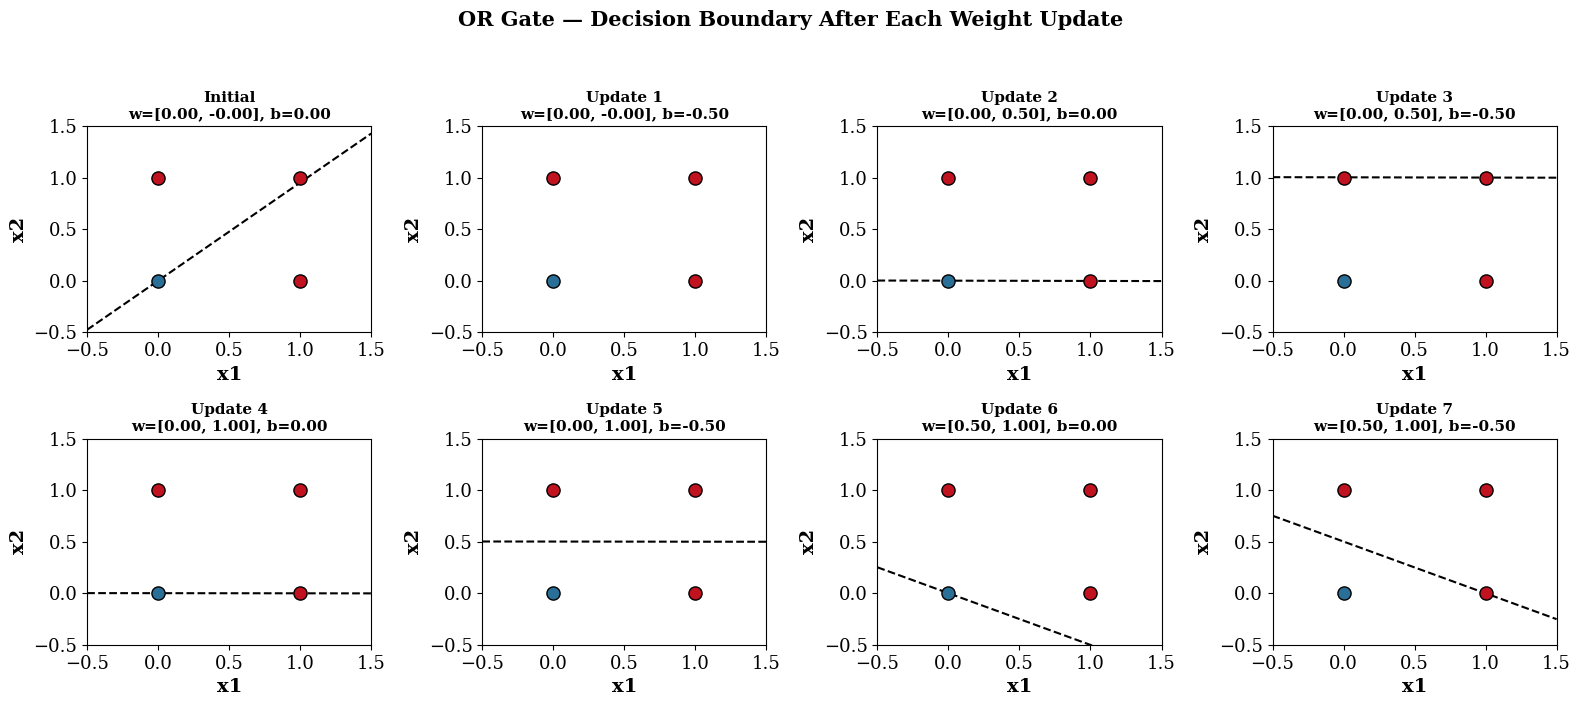

In [24]:
# --- OR gate ---------------------------------------------------------------
X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_or = np.array([0, 1, 1, 1])

or_snapshots, or_converged = train_with_update_history(X_or, y_or, learning_rate=0.5, random_state=0)
print(f"OR gate converged: {or_converged}  |  updates needed: {len(or_snapshots) - 1}")
for i, (w, b, idx) in enumerate(or_snapshots):
    tag = "initial" if idx is None else f"after update {i} (sample {idx}: x={X_or[idx]}, y={y_or[idx]})"
    print(f"  {tag}: weights={np.round(w, 3)}, bias={b:.3f}")

plot_gate_updates("OR", X_or, y_or, or_snapshots, ["x1", "x2"], "12_or_gate_updates")

AND gate converged: True  |  updates needed: 13
  initial: weights=[ 0.001 -0.001], bias=0.000
  after update 1 (sample 0: x=[0. 0.], y=0): weights=[ 0.001 -0.001], bias=-0.500
  after update 2 (sample 3: x=[1. 1.], y=1): weights=[0.501 0.499], bias=0.000
  after update 3 (sample 0: x=[0. 0.], y=0): weights=[0.501 0.499], bias=-0.500
  after update 4 (sample 2: x=[1. 0.], y=0): weights=[0.001 0.499], bias=-1.000
  after update 5 (sample 3: x=[1. 1.], y=1): weights=[0.501 0.999], bias=-0.500
  after update 6 (sample 1: x=[0. 1.], y=0): weights=[0.501 0.499], bias=-1.000
  after update 7 (sample 3: x=[1. 1.], y=1): weights=[1.001 0.999], bias=-0.500
  after update 8 (sample 1: x=[0. 1.], y=0): weights=[1.001 0.499], bias=-1.000
  after update 9 (sample 2: x=[1. 0.], y=0): weights=[0.501 0.499], bias=-1.500
  after update 10 (sample 3: x=[1. 1.], y=1): weights=[1.001 0.999], bias=-1.000
  after update 11 (sample 2: x=[1. 0.], y=0): weights=[0.501 0.999], bias=-1.500
  after update 12 (sam

Saved -> figures/13_and_gate_updates.eps


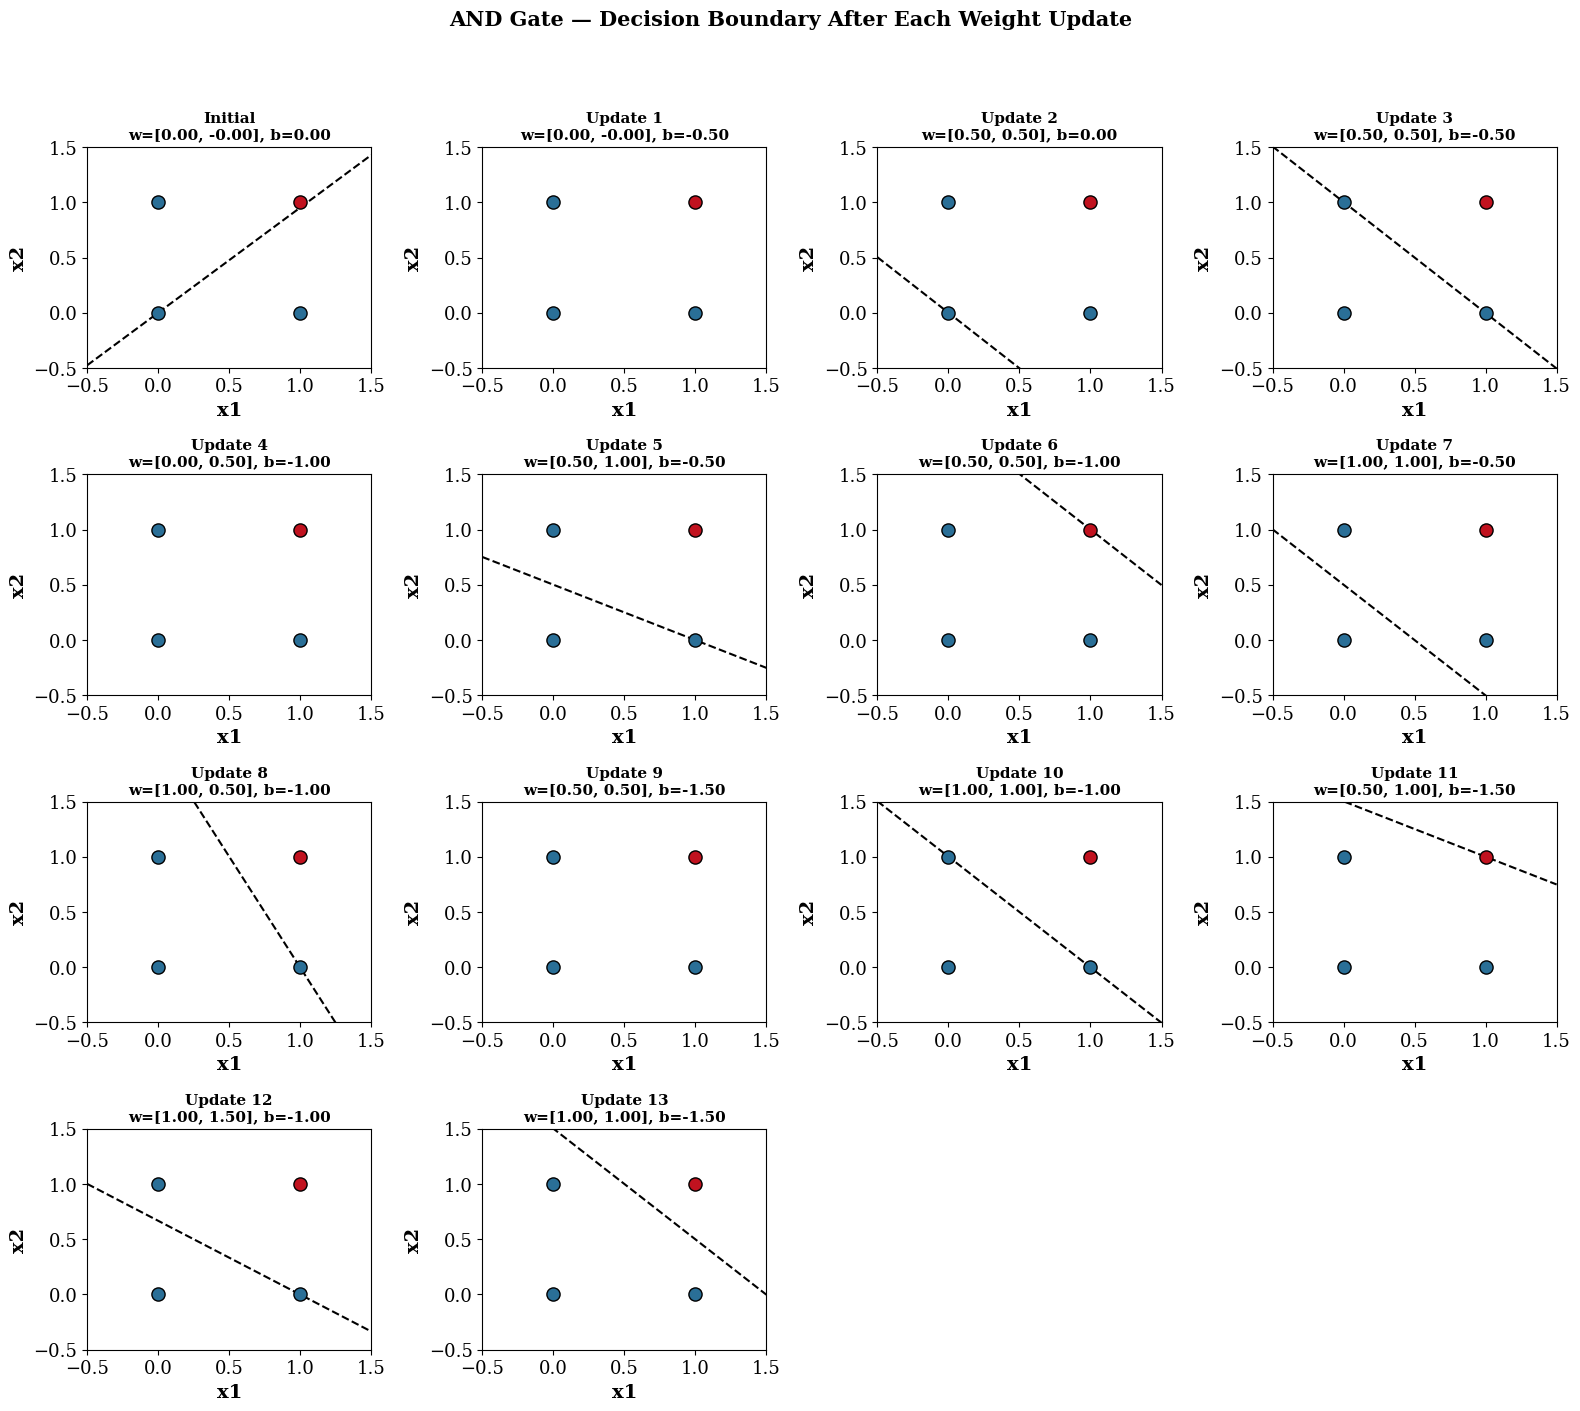

In [25]:
# --- AND gate ----------------------------------------------------------
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])

and_snapshots, and_converged = train_with_update_history(X_and, y_and, learning_rate=0.5, random_state=0)
print(f"AND gate converged: {and_converged}  |  updates needed: {len(and_snapshots) - 1}")
for i, (w, b, idx) in enumerate(and_snapshots):
    tag = "initial" if idx is None else f"after update {i} (sample {idx}: x={X_and[idx]}, y={y_and[idx]})"
    print(f"  {tag}: weights={np.round(w, 3)}, bias={b:.3f}")

plot_gate_updates("AND", X_and, y_and, and_snapshots, ["x1", "x2"], "13_and_gate_updates")

NOT gate converged: True  |  updates needed: 2
  initial: weights=[0.001], bias=0.000
  after update 1 (sample 1: x=[1.], y=0): weights=[-0.499], bias=-0.500
  after update 2 (sample 0: x=[0.], y=1): weights=[-0.499], bias=0.000


Saved -> figures/14_not_gate_updates.eps


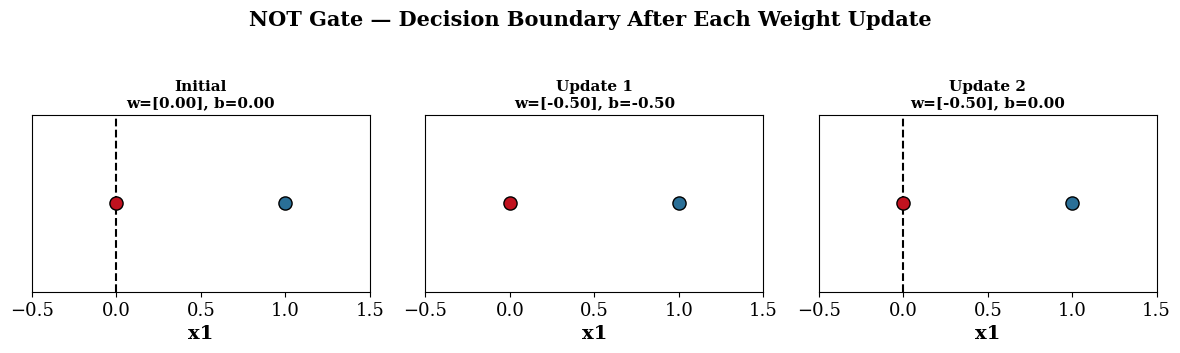

In [26]:
# --- NOT gate (single input) --------------------------------------------
X_not = np.array([[0], [1]], dtype=float)
y_not = np.array([1, 0])

not_snapshots, not_converged = train_with_update_history(X_not, y_not, learning_rate=0.5, random_state=0)
print(f"NOT gate converged: {not_converged}  |  updates needed: {len(not_snapshots) - 1}")
for i, (w, b, idx) in enumerate(not_snapshots):
    tag = "initial" if idx is None else f"after update {i} (sample {idx}: x={X_not[idx]}, y={y_not[idx]})"
    print(f"  {tag}: weights={np.round(w, 3)}, bias={b:.3f}")

plot_gate_updates("NOT", X_not, y_not, not_snapshots, ["x1"], "14_not_gate_updates")

XOR gate converged: False  |  updates taken before stopping: 16
  initial: weights=[ 0.001 -0.001], bias=0.000
  after update 1 (sample 0: x=[0. 0.], y=0): weights=[ 0.001 -0.001], bias=-0.500
  after update 2 (sample 1: x=[0. 1.], y=1): weights=[0.001 0.499], bias=0.000
  after update 3 (sample 3: x=[1. 1.], y=0): weights=[-0.499 -0.001], bias=-0.500
  after update 4 (sample 1: x=[0. 1.], y=1): weights=[-0.499  0.499], bias=0.000
  after update 5 (sample 2: x=[1. 0.], y=1): weights=[0.001 0.499], bias=0.500
  after update 6 (sample 3: x=[1. 1.], y=0): weights=[-0.499 -0.001], bias=0.000
  after update 7 (sample 0: x=[0. 0.], y=0): weights=[-0.499 -0.001], bias=-0.500
  after update 8 (sample 1: x=[0. 1.], y=1): weights=[-0.499  0.499], bias=0.000
  after update 9 (sample 2: x=[1. 0.], y=1): weights=[0.001 0.499], bias=0.500
  after update 10 (sample 3: x=[1. 1.], y=0): weights=[-0.499 -0.001], bias=0.000
  after update 11 (sample 0: x=[0. 0.], y=0): weights=[-0.499 -0.001], bias=-0.50

Saved -> figures/15_xor_gate_updates.eps


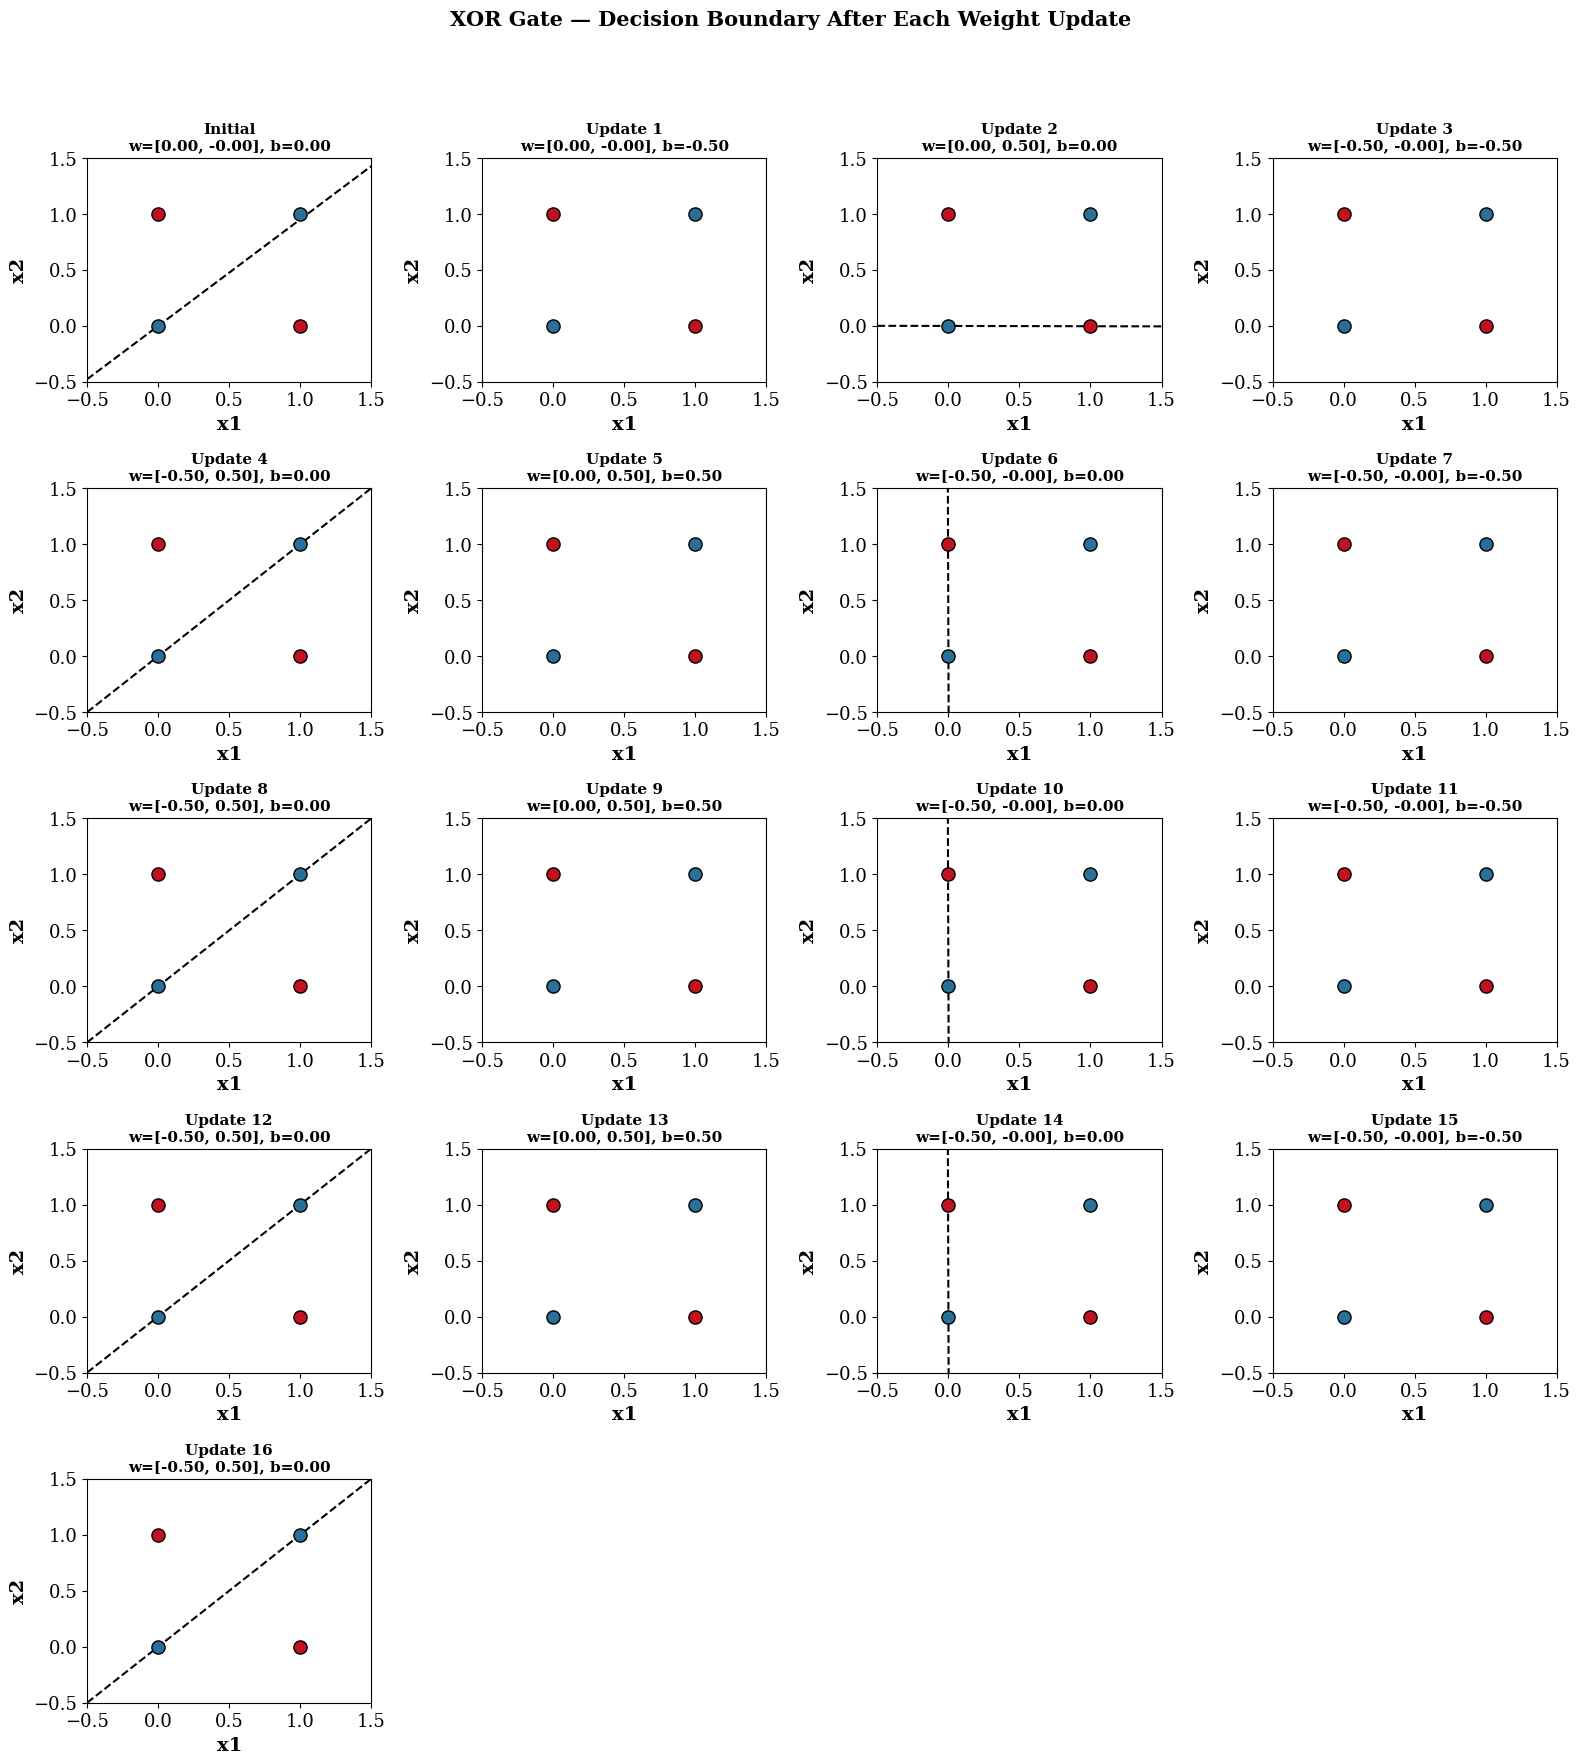

In [27]:
# --- XOR gate (does not converge) ---------------------------------------
X_xor_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor_gate = np.array([0, 1, 1, 0])

xor_snapshots, xor_converged = train_with_update_history(X_xor_gate, y_xor_gate, learning_rate=0.5,
                                                          max_updates=16, random_state=0)
print(f"XOR gate converged: {xor_converged}  |  updates taken before stopping: {len(xor_snapshots) - 1}")
for i, (w, b, idx) in enumerate(xor_snapshots):
    tag = "initial" if idx is None else f"after update {i} (sample {idx}: x={X_xor_gate[idx]}, y={y_xor_gate[idx]})"
    print(f"  {tag}: weights={np.round(w, 3)}, bias={b:.3f}")

plot_gate_updates("XOR", X_xor_gate, y_xor_gate, xor_snapshots, ["x1", "x2"], "15_xor_gate_updates")

**Why XOR never converges, geometrically:** XOR's four points are $(0,0)\to 0$, $(1,1)\to 0$ on one class, and $(0,1)\to 1$, $(1,0)\to 1$ on the other -- the two same-class pairs sit on opposite corners of the unit square, diagonal to each other. Any straight line drawn through that square either has both diagonal corners of one class on the same side (and then it's cut the other diagonal's two points onto opposite sides), or vice versa -- there is no way to draw one line that puts $(0,0)$ and $(1,1)$ together on one side while also putting $(0,1)$ and $(1,0)$ together on the other. That's the pattern the weight updates keep chasing: every correction that fixes one misclassified corner immediately breaks the diagonal corner that was previously correct, which is exactly the oscillation visible in the update panels above.

## Performance Summary Table

Everything the lab's "Training Summary" table asks for, pulled together from the objects we already trained above.

In [28]:
summary = {
    "Dataset Size": [len(df)],
    "Train/Test Split": ["80/20"],
    "Learning Rate": [model.learning_rate],
    "Epochs Run": [model.history["epoch"][-1]],
    "Final Weights": [np.round(model.weights, 4).tolist()],
    "Final Bias": [round(model.bias, 4)],
    "Accuracy": [round(metrics["Accuracy"], 4)],
    "Precision": [round(metrics["Precision"], 4)],
    "Recall": [round(metrics["Recall"], 4)],
    "F1-score": [round(metrics["F1-score"], 4)],
}
pd.DataFrame(summary).T.rename(columns={0: "Value"})

,Value
Dataset Size,1372
Train/Test Split,80/20
Learning Rate,0.01
Epochs Run,50
Final Weights,"[-0.2021, -0.2241, -0.1945, -0.0128]"
Final Bias,-0.09
Accuracy,0.9855
Precision,0.9683
Recall,1.0
F1-score,0.9839
